# 12 · Compare clean models and state the supported conclusions

Combine matching clean outer predictions, probability checks, decision workload and patient uncertainty. The main comparison uses clean models against clean models; historical duplicate sensitivity remains supporting evidence.

Read the stages in numerical order. Training uses separate, explicitly invoked runners; executing this notebook only loads development data and saved artifacts.

Original notebooks, images, checkpoints and results remain available. The reserved test is outside this workflow.

**Original methods and figure reference:** [08_metadata_robustness.ipynb](../Subset/08_metadata_robustness.ipynb), [14_image_nested_evaluation.ipynb](../Subset/14_image_nested_evaluation.ipynb). Read [method coverage](METHOD_COVERAGE.md) for retained methods and declared adaptations.

## Load the frozen clean development dataset

In [1]:
NOTEBOOK_STAGE = '12_combined_evaluation'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
FIGURE_DIR = ROOT / DIRECTORY / "figures" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=180, bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

## 1. Establish completion and provenance before comparing

A trained checkpoint alone is not a verified evaluation. Require dataset identity, matching image/patient/label/fold coverage, saved artifact fingerprints and reporting completion. Incomplete image stages remain pending and do not enter the final image-versus-metadata conclusion.

In [2]:
evaluation = latest_evaluation(ROOT)
bundle = score_bundle()
expected = bundle["expected"]
scores = bundle["scores"]
display(pd.DataFrame([evaluation.get("stages", {})]))
display(pd.DataFrame([{"evaluation_status":evaluation["status"], "matching_images":len(expected),
    "patients":expected.patient_id.nunique(),"malignant_images":int(expected.target.sum()),
    "dataset_manifest_sha256":dataset_identity["dataset_manifest_sha256"]}]))
assert len(expected) == 6706 and expected.image_id.is_unique
assert set(expected.image_id) == set(data.image_name)
for name, values in scores.items():
    assert len(values) == len(expected) and np.isfinite(values).all()
display(Markdown(evaluation.get("image_conclusion", "Clean comparison pending.")))

,metadata_core,metadata_suite,image_raw,image_calibration
0,complete,complete,complete,complete


,evaluation_status,matching_images,patients,malignant_images,dataset_manifest_sha256
0,complete,6706,422,127,9f7f0f3bfc436b90372c76c6925fbc12cdd8a413556d7e...


Clean B0 has the highest mean-fold AP among the three predeclared comparators (0.1316). Both paired AP intervals exclude zero in its favour. This supports reviewing B0 as the ranking choice on these development patients. Secondary tuned models and inner pilots do not automatically change the selected procedure. No reserved-test or clinical claim follows.

## 2. State the estimands and predeclared comparisons

Primary ranking results are unweighted mean-fold AP and ROC-AUC: compute each held-out fold's metric, then average the five numbers. Pooled metrics rank all OOF rows together and can be affected by differences in score scales across folds, so they are secondary. AP summarizes precision as recall increases; ROC-AUC summarizes ranking across both classes. Accuracy is unsuitable for this rare-positive target. Predeclared contrasts are B0 minus fixed spline, B0 minus the prescribed NN mean, and NN mean minus spline.

,population,model,aggregation,fold,weighting,n_images,n_patients,n_malignant_images,n_malignant_patients,average_precision,roc_auc,log_loss,brier,role
0,clean,ablation_age,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.045769,0.655074,0.091558,0.018454,secondary
1,clean,ablation_age_site,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.063622,0.666526,0.090723,0.018423,secondary
2,clean,ablation_all_features,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.064842,0.655631,0.091006,0.018422,secondary
3,clean,ablation_sex,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.021911,0.551898,0.093819,0.018587,secondary
4,clean,ablation_sex_age,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.045641,0.631247,0.091890,0.018461,secondary
5,clean,ablation_sex_site,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.033656,0.586431,0.092613,0.018524,secondary
6,clean,ablation_site,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.029049,0.562516,0.092716,0.018533,secondary
7,clean,b0_raw,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.131570,0.830801,0.099116,0.019637,predeclared
8,clean,categorical_logistic,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.056685,0.596946,0.092438,0.018490,secondary
9,clean,dummy,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.018950,0.500000,0.093934,0.018591,secondary


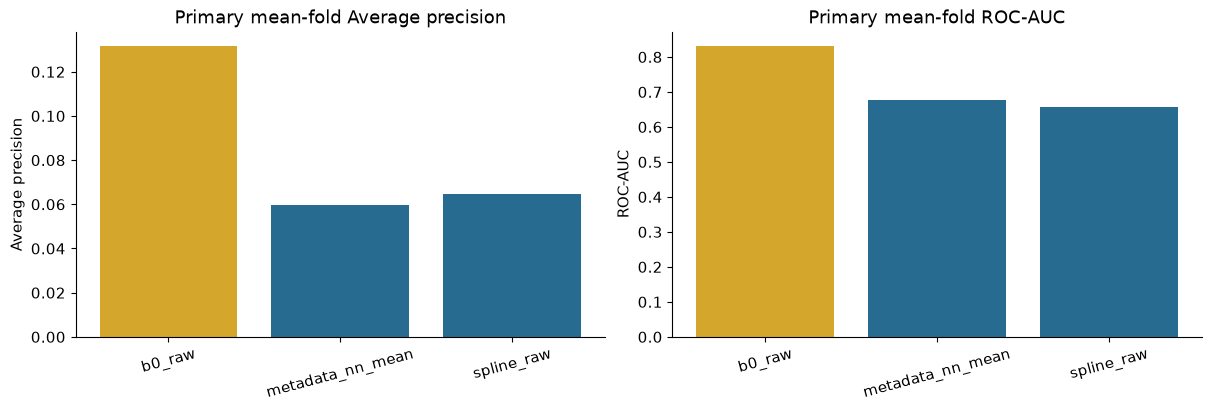

In [3]:
table = comparison_table()
display(table)
core_names=["b0_raw","spline_raw","metadata_nn_mean"]
core=table.loc[table.model.isin(core_names)]
fig,axes=plt.subplots(1,2,figsize=(12,4),layout="constrained")
for ax,metric,label in [(axes[0],"average_precision","Average precision"),(axes[1],"roc_auc","ROC-AUC")]:
    ax.bar(core.model,core[metric],color=["#276b91" if n!="b0_raw" else "#d4a72c" for n in core.model])
    ax.set(title="Primary mean-fold "+label,ylabel=label); ax.tick_params(axis="x",rotation=15)
finish_figure(fig,"core_mean_fold_ap_auc")
if "b0_raw" not in scores: display(Markdown("**Pending:** B0 has not supplied all five verified outer predictions; current bars show metadata only."))

## 3. Read fold variation and pooled curves

Replicate the original fold tables, ROC and precision–recall views on matching clean records. Curves here pool OOF scores and are secondary illustrations, while mean-fold metrics remain primary. A dashed prevalence line provides the constant-score reference for precision–recall. Fold variability can be large when only 24–26 malignant images occur in a group.

,model,fold,n_images,n_malignant_images,n_malignant_patients,average_precision,roc_auc
0,metadata_nn_mean,0,1344.0,24.0,17.0,0.053464,0.761064
2,spline_raw,0,1344.0,24.0,17.0,0.066199,0.794397
40,b0_raw,0,1344.0,24.0,17.0,0.152537,0.854419
42,metadata_nn_mean,1,1366.0,26.0,15.0,0.057538,0.655066
44,spline_raw,1,1366.0,26.0,15.0,0.046026,0.558797
82,b0_raw,1,1366.0,26.0,15.0,0.148876,0.839179
84,metadata_nn_mean,2,1328.0,26.0,21.0,0.042187,0.668011
86,spline_raw,2,1328.0,26.0,21.0,0.037312,0.631130
124,b0_raw,2,1328.0,26.0,21.0,0.148730,0.864823
126,metadata_nn_mean,3,1371.0,25.0,18.0,0.059744,0.689421


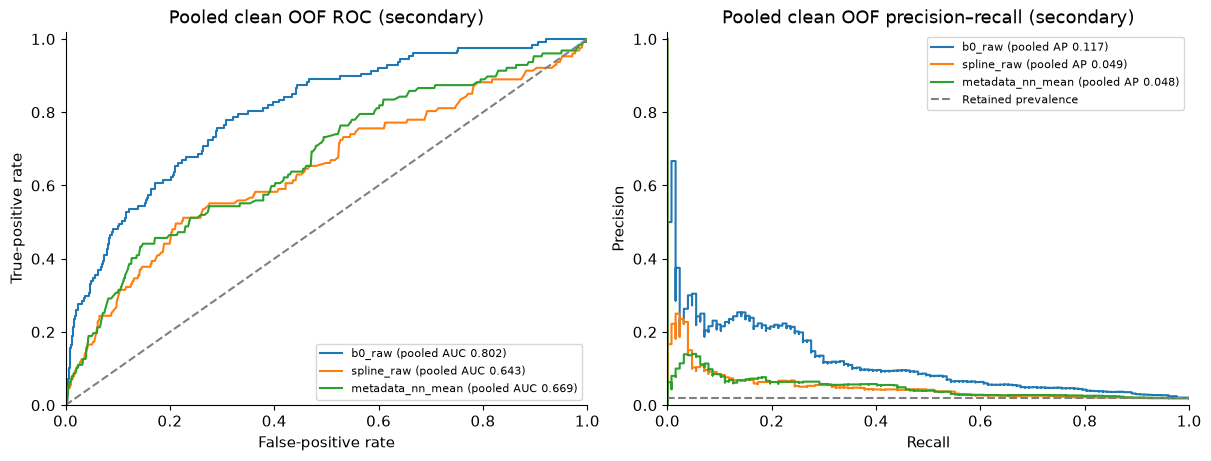

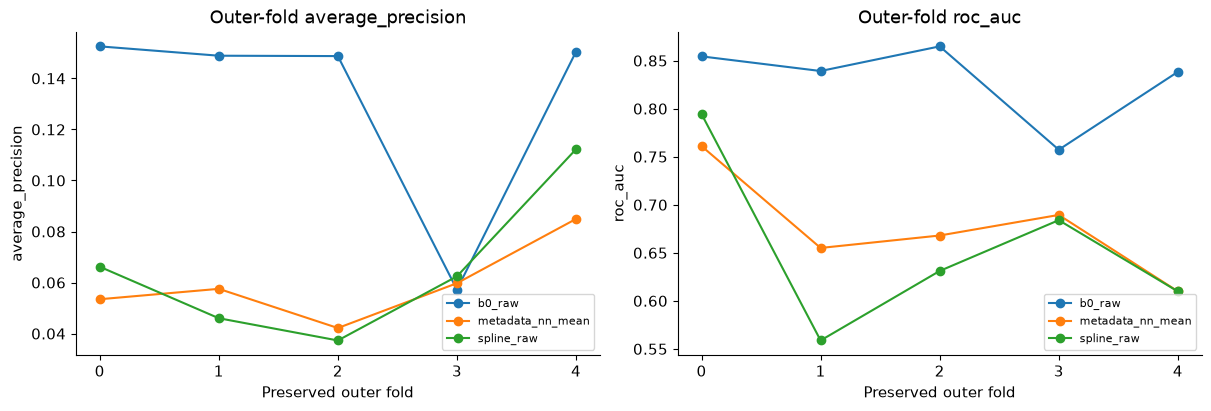

In [4]:
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score, roc_auc_score
directory=project_path(ROOT,evaluation["output_directory"])
metrics=pd.read_csv(directory/"metrics.csv")
by_fold=metrics.loc[metrics.model.isin(core_names)&metrics.aggregation.eq("by_fold")&metrics.weighting.eq("image")]
display(by_fold[["model","fold","n_images","n_malignant_images","n_malignant_patients","average_precision","roc_auc"]])
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout="constrained")
for name in core_names:
    if name not in scores: continue
    fpr,tpr,_=roc_curve(expected.target,scores[name]); precision,recall,_=precision_recall_curve(expected.target,scores[name])
    axes[0].plot(fpr,tpr,label=f"{name} (pooled AUC {roc_auc_score(expected.target,scores[name]):.3f})")
    axes[1].step(recall,precision,where="post",label=f"{name} (pooled AP {average_precision_score(expected.target,scores[name]):.3f})")
axes[0].plot([0,1],[0,1],"--",color="grey"); axes[1].axhline(expected.target.mean(),ls="--",color="grey",label="Retained prevalence")
axes[0].set(title="Pooled clean OOF ROC (secondary)",xlabel="False-positive rate",ylabel="True-positive rate")
axes[1].set(title="Pooled clean OOF precision–recall (secondary)",xlabel="Recall",ylabel="Precision")
for ax in axes: ax.set_xlim(0,1); ax.set_ylim(0,1.02); ax.legend(fontsize=8)
finish_figure(fig,"core_roc_precision_recall")
fig,axes=plt.subplots(1,2,figsize=(12,4),layout="constrained")
for name,rows in by_fold.groupby("model"):
    for ax,metric in zip(axes,["average_precision","roc_auc"]): ax.plot(rows.fold.astype(int),rows[metric],marker="o",label=name)
for ax,metric in zip(axes,["average_precision","roc_auc"]): ax.set(title="Outer-fold "+metric,xlabel="Preserved outer fold",ylabel=metric,xticks=range(5)); ax.legend(fontsize=8)
finish_figure(fig,"core_fold_variation")

## 4. Use paired whole-patient intervals

Sample patients with replacement within each outer fold for 2,000 draws, seed 42, and copy all their retained images together. Every model receives the same patient multiplicities on a draw. For a difference, compute A minus B on each draw, then use its 2.5th and 97.5th percentiles. Record invalid single-class draws. Intervals condition on these saved models and omit training/selection uncertainty; they do not establish clinical benefit.

,comparison,aggregation,metric,difference,ci_lower,ci_upper,bootstrap_replicates,valid_replicates,rejected_single_class_replicates,seed,role
0,b0_raw minus metadata_nn_mean,mean_fold,average_precision,0.071999,0.022864,0.148646,2000,2000,0,42,predeclared development comparison
1,b0_raw minus metadata_nn_mean,mean_fold,roc_auc,0.154107,0.092697,0.207803,2000,2000,0,42,predeclared development comparison
8,b0_raw minus spline_raw,mean_fold,average_precision,0.066728,0.010437,0.145808,2000,2000,0,42,predeclared development comparison
9,b0_raw minus spline_raw,mean_fold,roc_auc,0.175170,0.105800,0.232184,2000,2000,0,42,predeclared development comparison
16,metadata_nn_mean minus spline_raw,mean_fold,average_precision,-0.005271,-0.025522,0.007595,2000,2000,0,42,predeclared development comparison
17,metadata_nn_mean minus spline_raw,mean_fold,roc_auc,0.021063,-0.005631,0.041326,2000,2000,0,42,predeclared development comparison


,model,aggregation,metric,estimate,ci_lower,ci_upper,bootstrap_replicates,valid_replicates,rejected_single_class_replicates,seed,interval
0,metadata_nn_mean,mean_fold,average_precision,0.059570,0.044039,0.105900,2000,2000,0,42,"95% percentile, conditional patient-cluster bo..."
1,metadata_nn_mean,mean_fold,roc_auc,0.676694,0.614121,0.735503,2000,2000,0,42,"95% percentile, conditional patient-cluster bo..."
8,spline_raw,mean_fold,average_precision,0.064842,0.045574,0.115039,2000,2000,0,42,"95% percentile, conditional patient-cluster bo..."
9,spline_raw,mean_fold,roc_auc,0.655631,0.593995,0.720417,2000,2000,0,42,"95% percentile, conditional patient-cluster bo..."
16,b0_raw,mean_fold,average_precision,0.131570,0.094697,0.218854,2000,2000,0,42,"95% percentile, conditional patient-cluster bo..."
17,b0_raw,mean_fold,roc_auc,0.830801,0.787076,0.865113,2000,2000,0,42,"95% percentile, conditional patient-cluster bo..."


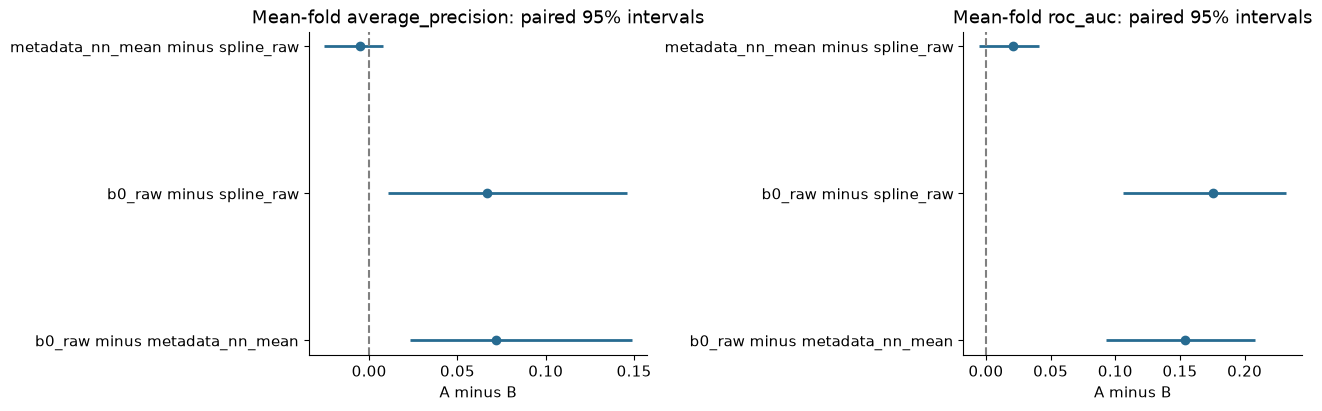

In [5]:
intervals=pd.read_csv(directory/"bootstrap_intervals.csv")
comparisons=pd.read_csv(directory/"paired_comparisons.csv")
primary=comparisons.loc[comparisons.aggregation.eq("mean_fold")&comparisons.metric.isin(["average_precision","roc_auc"])]
display(primary)
display(intervals.loc[intervals.aggregation.eq("mean_fold")&intervals.metric.isin(["average_precision","roc_auc"])])
fig,axes=plt.subplots(1,2,figsize=(13,4),layout="constrained")
for ax,metric in zip(axes,["average_precision","roc_auc"]):
    selected=primary.loc[primary.metric.eq(metric)].reset_index(drop=True)
    pos=np.arange(len(selected))
    ax.hlines(pos,selected.ci_lower,selected.ci_upper,color="#276b91",linewidth=2)
    ax.scatter(selected.difference,pos,color="#276b91"); ax.axvline(0,color="grey",ls="--")
    ax.set(yticks=pos,yticklabels=selected.comparison,xlabel="A minus B",title="Mean-fold "+metric+": paired 95% intervals")
finish_figure(fig,"core_paired_patient_intervals")

## 5. Separate patient weighting from patient-level prediction

As a secondary diagnostic, give each image weight 1 divided by that patient's retained image count. This makes total image weight equal across patients while keeping the image-level target. It does not turn an image score into a patient diagnosis. Compare with conventional image-weighted results on the same records; never select a model merely because one weighting is favourable.

,model,weighting,average_precision,roc_auc
266,b0_raw,equal_patient,0.192361,0.792627
267,b0_raw,image,0.131570,0.830801
272,metadata_nn_mean,equal_patient,0.115317,0.720950
273,metadata_nn_mean,image,0.059570,0.676694
286,spline_raw,equal_patient,0.127097,0.706556
287,spline_raw,image,0.064842,0.655631


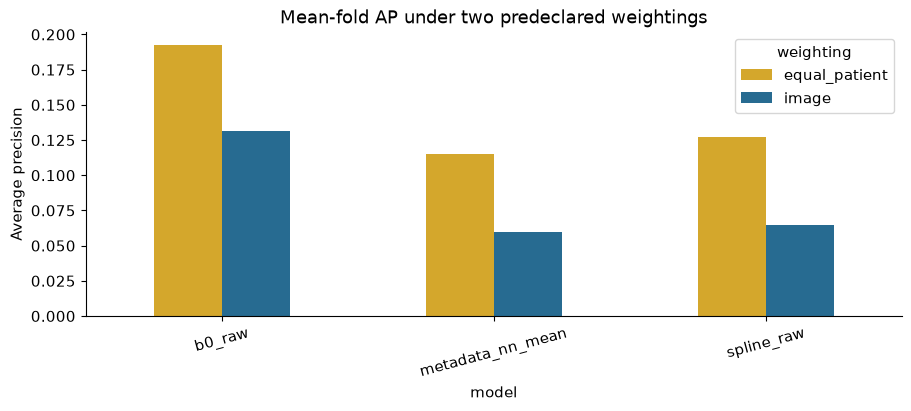

In [6]:
weighted=metrics.loc[metrics.model.isin(core_names)&metrics.aggregation.eq("mean_fold")]
display(weighted[["model","weighting","average_precision","roc_auc"]])
pivot=weighted.pivot(index="model",columns="weighting",values="average_precision")
fig,ax=plt.subplots(figsize=(9,4),layout="constrained")
pivot.plot.bar(ax=ax,color=["#d4a72c","#276b91"],rot=15)
ax.set(title="Mean-fold AP under two predeclared weightings",ylabel="Average precision")
finish_figure(fig,"equal_patient_weight_ap")

## 6. Assess probabilities and training-only decision workload

Ranking, calibration and decisions answer different questions. Brier and log loss assess probability quality; calibration maps and recall cutoffs must be learned inside each outer-training pool. Combine the resulting outer decisions without searching for a better cutoff on the reported OOF labels. Read recall beside precision and the number of images flagged. A fixed 0.5 cutoff is a diagnostic rather than the main recall scenario.

,model,log_loss,brier
267,b0_raw,0.099116,0.019637
273,metadata_nn_mean,0.090169,0.018382
285,spline_calibrated,0.090830,0.018410
287,spline_raw,0.091006,0.018422


,model,score_scale,fold,n_images,n_patients,malignant_images,malignant_patients,n_flagged,cutoff_minimum,cutoff_maximum,...,brier,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction,cutoff_source
0,fixed_spline,p_spline_raw,0,1344,84,24,17,1123,0.010618,0.010618,...,0.017236,24,1099,221,0,1.000000,0.167424,0.021371,0.835565,training-only OOF; academic target recall 0.8
1,fixed_spline,p_spline_raw,1,1366,84,26,15,819,0.011326,0.011326,...,0.018746,17,802,538,9,0.653846,0.401493,0.020757,0.599561,training-only OOF; academic target recall 0.8
2,fixed_spline,p_spline_raw,2,1328,87,26,21,853,0.009737,0.009737,...,0.019201,21,832,470,5,0.807692,0.360983,0.024619,0.642319,training-only OOF; academic target recall 0.8
3,fixed_spline,p_spline_raw,3,1371,82,25,18,1129,0.010137,0.010137,...,0.017571,22,1107,239,3,0.880000,0.177563,0.019486,0.823487,training-only OOF; academic target recall 0.8
4,fixed_spline,p_spline_raw,4,1297,85,26,17,673,0.011971,0.011971,...,0.019355,18,655,616,8,0.692308,0.484658,0.026746,0.518890,training-only OOF; academic target recall 0.8
5,fixed_spline,p_spline_raw,pooled,6706,422,127,88,4597,0.009737,0.011971,...,0.018411,102,4495,2084,25,0.803150,0.316765,0.022188,0.685506,training-only OOF; academic target recall 0.8
6,fixed_spline,p_spline_calibrated,0,1344,84,24,17,1123,0.013546,0.013546,...,0.017272,24,1099,221,0,1.000000,0.167424,0.021371,0.835565,training-only OOF; academic target recall 0.8
7,fixed_spline,p_spline_calibrated,1,1366,84,26,15,819,0.012907,0.012907,...,0.018589,17,802,538,9,0.653846,0.401493,0.020757,0.599561,training-only OOF; academic target recall 0.8
8,fixed_spline,p_spline_calibrated,2,1328,87,26,21,853,0.011535,0.011535,...,0.019103,21,832,470,5,0.807692,0.360983,0.024619,0.642319,training-only OOF; academic target recall 0.8
9,fixed_spline,p_spline_calibrated,3,1371,82,25,18,1129,0.011808,0.011808,...,0.017630,22,1107,239,3,0.880000,0.177563,0.019486,0.823487,training-only OOF; academic target recall 0.8


,model,cutoff,role,n_flagged,TP,FP,TN,FN,sensitivity,specificity,precision,flagged_fraction
0,metadata_nn_mean,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
1,spline_raw,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
2,nn_seed_42,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
3,nn_seed_142,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
4,nn_seed_242,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
5,dummy,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
6,categorical_logistic,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
7,random_forest,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
8,xgboost,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0
9,ablation_sex,0.5,fixed descriptive diagnostic,0,0,0,6579,127,0.0,1.0,NaN,0.0


Showing 12 of 21 rows; the complete CSV is saved.

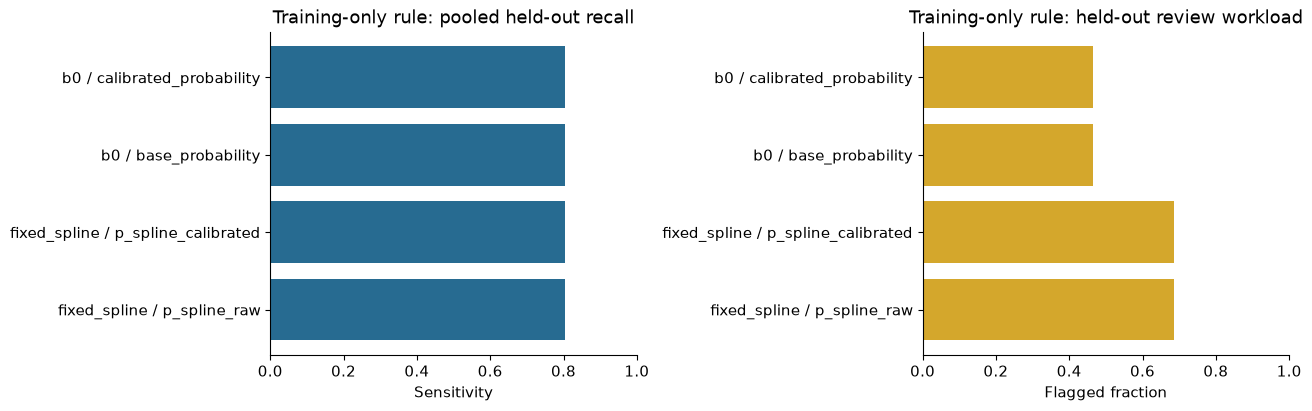

In [7]:
display(metrics.loc[metrics.aggregation.eq("mean_fold")&metrics.weighting.eq("image")&metrics.model.isin(
    ["b0_raw","spline_raw","metadata_nn_mean","spline_calibrated"]),["model","log_loss","brier"]])
decisions=pd.read_csv(directory/"training_only_cutoff_metrics.csv")
display(decisions)
show_saved_table(evaluation["output_directory"]+"/fixed_cutoff_05.csv",12)
selected=decisions.loc[decisions.fold.astype(str).eq("pooled")].copy()
if not selected.empty:
    labels=selected.model+" / "+selected.score_scale
    fig,axes=plt.subplots(1,2,figsize=(13,4),layout="constrained")
    axes[0].barh(labels,selected.sensitivity,color="#276b91"); axes[0].set(title="Training-only rule: pooled held-out recall",xlabel="Sensitivity",xlim=(0,1))
    axes[1].barh(labels,selected.flagged_fraction,color="#d4a72c"); axes[1].set(title="Training-only rule: held-out review workload",xlabel="Flagged fraction",xlim=(0,1))
    finish_figure(fig,"training_only_recall_workload")
if evaluation.get("stages",{}).get("image_calibration") != "complete": display(Markdown("**Pending:** clean image calibration and cutoffs are not yet complete. Metadata decisions above are the available training-only procedure."))

## 7. Inspect subgroup support before performance

Recreate the age, sex, anatomical-site and known/unknown-site diagnostics. Subgroup results are pooled and descriptive; no subgroup-specific rule is tuned. Display image and malignant-patient counts together. A subgroup with only two malignant patients cannot justify a strong comparative conclusion, and undefined metrics remain missing rather than zero.

,population,axis,subgroup,model,n_images,n_patients,n_malignant_images,n_malignant_patients,average_precision,roc_auc,log_loss,brier,interpretation
0,clean,site_knownness,known,metadata_nn_mean,6511,421,125,87,0.048308,0.672219,0.091033,0.018614,descriptive pooled subgroup; support can be sp...
1,clean,site_knownness,known,spline_raw,6511,421,125,87,0.049778,0.644730,0.091876,0.018656,descriptive pooled subgroup; support can be sp...
20,clean,site_knownness,known,b0_raw,6511,421,125,87,0.115698,0.797092,0.101342,0.019942,descriptive pooled subgroup; support can be sp...
21,clean,site_knownness,unknown,metadata_nn_mean,195,53,2,2,0.011004,0.326425,0.059147,0.010234,descriptive pooled subgroup; support can be sp...
22,clean,site_knownness,unknown,spline_raw,195,53,2,2,0.077718,0.582902,0.060004,0.010247,descriptive pooled subgroup; support can be sp...
41,clean,site_knownness,unknown,b0_raw,195,53,2,2,0.375000,0.981865,0.032960,0.009337,descriptive pooled subgroup; support can be sp...
42,clean,anatomical_site,Missing,metadata_nn_mean,195,53,2,2,0.011004,0.326425,0.059147,0.010234,descriptive pooled subgroup; support can be sp...
43,clean,anatomical_site,Missing,spline_raw,195,53,2,2,0.077718,0.582902,0.060004,0.010247,descriptive pooled subgroup; support can be sp...
62,clean,anatomical_site,Missing,b0_raw,195,53,2,2,0.375000,0.981865,0.032960,0.009337,descriptive pooled subgroup; support can be sp...
63,clean,anatomical_site,head/neck,metadata_nn_mean,393,179,21,21,0.116937,0.693740,0.198117,0.049501,descriptive pooled subgroup; support can be sp...


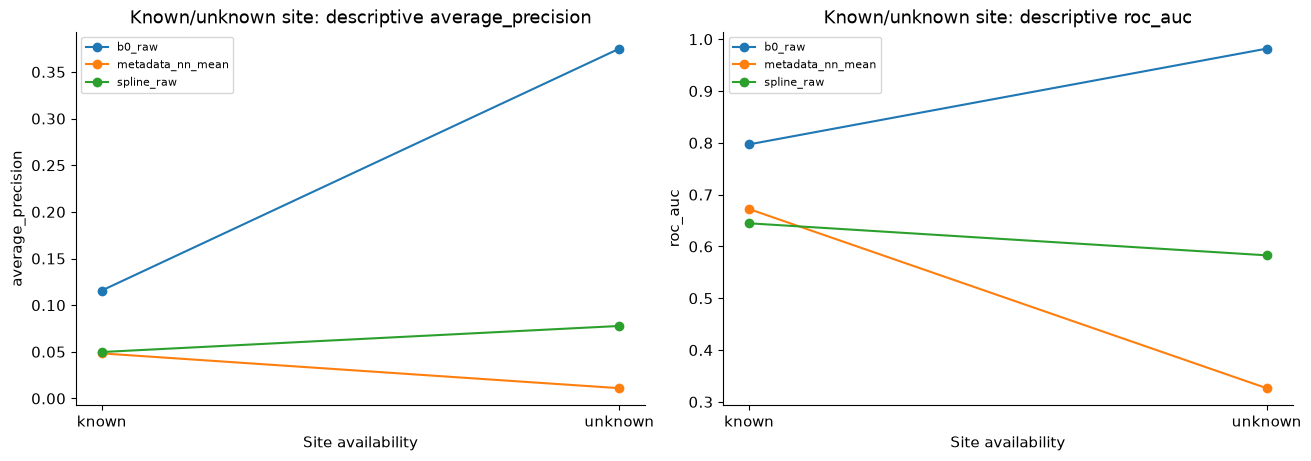

,subgroup,model,n_images,n_patients,n_malignant_images,n_malignant_patients
0,known,metadata_nn_mean,6511,421,125,87
1,known,spline_raw,6511,421,125,87
20,known,b0_raw,6511,421,125,87
21,unknown,metadata_nn_mean,195,53,2,2
22,unknown,spline_raw,195,53,2,2
41,unknown,b0_raw,195,53,2,2


In [8]:
subgroups=pd.read_csv(directory/"subgroups.csv")
selected=subgroups.loc[subgroups.model.isin(core_names)]
display(selected)
fig,axes=plt.subplots(1,2,figsize=(13,4.5),layout="constrained")
known=selected.loc[selected.axis.eq("site_knownness")]
for ax,metric in zip(axes,["average_precision","roc_auc"]):
    for name,rows in known.groupby("model"):
        ax.plot(rows.subgroup,rows[metric],marker="o",label=name)
    ax.set(title="Known/unknown site: descriptive "+metric,xlabel="Site availability",ylabel=metric); ax.legend(fontsize=8)
finish_figure(fig,"known_unknown_site_core")
display(known[["subgroup","model","n_images","n_patients","n_malignant_images","n_malignant_patients"]])

## 8. Keep tuning, pilots and uncertainty in their proper roles

Wider metadata searches and feature ablations are secondary. B0/ConvNeXt duration pilots use selected inner validation and cannot establish a final architecture winner. MC-dropout/TTA referral describes uncertainty and error ordering from matching clean checkpoints; its averages do not automatically replace calibrated decision scores. Stronger augmentation, CLAHE, resolution changes, full challenger OOF and fusion remain deferred.

In [9]:
secondary=table.loc[~table.model.isin(core_names)]
display(secondary)
statuses=[]
for run in ["b0_duration_dedup_v1","convnext_duration_dedup_v1"]:
    _,record=pilot_report(run); statuses.append({"stage":run,"status":record.get("status","pending"),"evidence":"selected inner validation"})
uncertainty=load_uncertainty_report(ROOT)
statuses.append({"stage":"clean_uncertainty","status":uncertainty["status"],"evidence":"descriptive outer-held-out inference"})
display(pd.DataFrame(statuses))
display(Markdown("Read stages 07, 10 and 11 for their full diagnostics; these secondary observations cannot automatically change the locked primary comparison."))

,population,model,aggregation,fold,weighting,n_images,n_patients,n_malignant_images,n_malignant_patients,average_precision,roc_auc,log_loss,brier,role
0,clean,ablation_age,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.045769,0.655074,0.091558,0.018454,secondary
1,clean,ablation_age_site,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.063622,0.666526,0.090723,0.018423,secondary
2,clean,ablation_all_features,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.064842,0.655631,0.091006,0.018422,secondary
3,clean,ablation_sex,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.021911,0.551898,0.093819,0.018587,secondary
4,clean,ablation_sex_age,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.045641,0.631247,0.091890,0.018461,secondary
5,clean,ablation_sex_site,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.033656,0.586431,0.092613,0.018524,secondary
6,clean,ablation_site,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.029049,0.562516,0.092716,0.018533,secondary
8,clean,categorical_logistic,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.056685,0.596946,0.092438,0.018490,secondary
9,clean,dummy,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.018950,0.500000,0.093934,0.018591,secondary
11,clean,nn_seed_142,mean_fold,mean_fold,image,NaN,NaN,NaN,NaN,0.058838,0.674086,0.090312,0.018381,secondary


,stage,status,evidence
0,b0_duration_dedup_v1,pending,selected inner validation
1,convnext_duration_dedup_v1,pending,selected inner validation
2,clean_uncertainty,complete,descriptive outer-held-out inference


Read stages 07, 10 and 11 for their full diagnostics; these secondary observations cannot automatically change the locked primary comparison.

## 9. Explain what duplicate sensitivity proves

The saved historical prediction analysis removes copies from evaluation only. Clean retraining also removes their training and selection weight. The main report here compares clean models; the sensitivity appendix provides a traceable check without replacing the clean experiment. The reserved test and final all-development fit remain outside this analysis.

In [10]:
display(Markdown("[Saved-prediction sensitivity appendix](../../results/dedup_v1/sensitivity/saved_oof_v2/report.md). Retained historical scores were preserved exactly; they were not averaged or selected for favourable performance."))
display(Markdown(evaluation.get("image_conclusion","Clean image comparison pending.")))
display(Markdown("**Final reporting rule:** no image-versus-metadata conclusion until the required clean OOF and calibration stages are verified. Freeze the procedure before a separate final fit and any later reserved-test evaluation."))

[Saved-prediction sensitivity appendix](../../results/dedup_v1/sensitivity/saved_oof_v2/report.md). Retained historical scores were preserved exactly; they were not averaged or selected for favourable performance.

Clean B0 has the highest mean-fold AP among the three predeclared comparators (0.1316). Both paired AP intervals exclude zero in its favour. This supports reviewing B0 as the ranking choice on these development patients. Secondary tuned models and inner pilots do not automatically change the selected procedure. No reserved-test or clinical claim follows.

**Final reporting rule:** no image-versus-metadata conclusion until the required clean OOF and calibration stages are verified. Freeze the procedure before a separate final fit and any later reserved-test evaluation.

## 10. Check reproducibility and hand off

Keep manifests, predictions, histories, calibration maps and figures under separate clean identities. The notebooks provide editable plotting code and export PNG/PDF figures, while run receipts identify the fitting implementation and saved inputs. Historical files remain byte-identical. A pending stage is explicitly incomplete, not a negative result.

In [11]:
receipt_path=ROOT / DIRECTORY / "preservation_receipt.json"
if receipt_path.exists(): display(pd.DataFrame([read_json(receipt_path)]))
display(pd.DataFrame([{"saved_evaluation_directory":evaluation["output_directory"],"stage_figure_directory":str(FIGURE_DIR),
    "training_started_by_notebook":False,"reserved_test_loaded":False}]))
display(Markdown("The clean procedure is ready for interpretation only to the extent of its verified completion. Keep original and clean outputs together when documenting limitations and provenance."))

,status,historical_artifacts_verified,historical_notebooks_verified,dataset_manifest_sha256,reserved_test_loaded
0,complete,8143,24,9f7f0f3bfc436b90372c76c6925fbc12cdd8a413556d7e...,False


,saved_evaluation_directory,stage_figure_directory,training_started_by_notebook,reserved_test_loaded
0,results/dedup_v1/clean_workflow/evaluation/f1f...,C:\Users\thoma\Documents\GitHub\ADS2002-Melano...,False,False


The clean procedure is ready for interpretation only to the extent of its verified completion. Keep original and clean outputs together when documenting limitations and provenance.

## Interpretation boundary

These are development results. Patient grouping protects separation between fitting and validation; bootstrap intervals condition on saved models. Sparse subgroups and selected inner-validation pilots cannot establish a final winner. No reserved-test conclusion is made.